In [ ]:
!pip install tensorflow kagglehub

In [21]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm import tqdm

import kagglehub

from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

from tensorflow.keras.models import Model

# LOAD DATASET

In [22]:
path = kagglehub.dataset_download(
    "ibrahimagabardiop/niayes-crops-disease-v2"
)

print(path)

100%|██████████| 1.55G/1.55G [01:28<00:00, 18.8MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/ibrahimagabardiop/niayes-crops-disease-v2/versions/1


# PREPROCESSING

### Cek Struktur Dataset

In [23]:
print(os.listdir(path))

['train', 'labels.csv', 'test', 'val']


In [24]:
train_path = os.path.join(path, "train")

classes = sorted(os.listdir(train_path))

print("Jumlah Kelas :", len(classes))

for cls in classes:
    print(cls)

Jumlah Kelas : 36
Bell_pepper__Bell_pepper_Bacterial_spot
Bell_pepper__Bell_pepper_Healthy
Brinjal__Diseased_Brinjal_Leaf_-_Cercospora_Leaf_Spot
Brinjal__Fresh_Brinjal_Leaf
Cabbage__Alternaria_Leaf_Spot
Cabbage__Bacterial_spot_rot
Cabbage__Black_Rot
Cabbage__Cabbage_aphid_colony
Cabbage__Downy_Mildew
Cabbage__Healthy
Cabbage__club_root
Cabbage__ring_spot
Citrus__Citrus_Black_spot
Citrus__Citrus_Healthy
Citrus__Citrus_canker
Citrus__Citrus_greening
Corn__Corn_Common_rust
Corn__Corn_Gray_leaf_spot
Corn__Corn_Healthy
Corn__Corn_Northern_Leaf_Blight
Lettuce__Bacterial
Lettuce__fungal
Lettuce__healthy
Potato__Potato_Early_blight
Potato__Potato_Healthy
Potato__Potato_Late_blight
Tomato__Tomato_Bacterial_spot
Tomato__Tomato_Early_blight
Tomato__Tomato_Healthy
Tomato__Tomato_Late_blight
Tomato__Tomato_Leaf_Mold
Tomato__Tomato_Mosaic_virus
Tomato__Tomato_Septoria_leaf_spot
Tomato__Tomato_Spider_mites
Tomato__Tomato_Target_Spot
Tomato__Tomato_Yellow_Leaf_Curl_Virus


### Membuat DataFrame Training


In [25]:
train_path = os.path.join(path, "train")

train_data = []

for cls in sorted(os.listdir(train_path)):

    class_folder = os.path.join(train_path, cls)

    for img in os.listdir(class_folder):

        train_data.append([
            os.path.join(class_folder, img),
            cls
        ])

train_df = pd.DataFrame(
    train_data,
    columns=[
        "image_path",
        "class_name"
    ]
)

train_df.head()

,image_path,class_name
0,/root/.cache/kagglehub/datasets/ibrahimagabard...,Bell_pepper__Bell_pepper_Bacterial_spot
1,/root/.cache/kagglehub/datasets/ibrahimagabard...,Bell_pepper__Bell_pepper_Bacterial_spot
2,/root/.cache/kagglehub/datasets/ibrahimagabard...,Bell_pepper__Bell_pepper_Bacterial_spot
3,/root/.cache/kagglehub/datasets/ibrahimagabard...,Bell_pepper__Bell_pepper_Bacterial_spot
4,/root/.cache/kagglehub/datasets/ibrahimagabard...,Bell_pepper__Bell_pepper_Bacterial_spot


### Membuat DataFrame Validation

In [26]:
val_path = os.path.join(path, "val")

val_data = []

for cls in sorted(os.listdir(val_path)):

    class_folder = os.path.join(val_path, cls)

    for img in os.listdir(class_folder):

        val_data.append([
            os.path.join(class_folder, img),
            cls
        ])

val_df = pd.DataFrame(
    val_data,
    columns=[
        "image_path",
        "class_name"
    ]
)

val_df.head()

,image_path,class_name
0,/root/.cache/kagglehub/datasets/ibrahimagabard...,Bell_pepper__Bell_pepper_Bacterial_spot
1,/root/.cache/kagglehub/datasets/ibrahimagabard...,Bell_pepper__Bell_pepper_Bacterial_spot
2,/root/.cache/kagglehub/datasets/ibrahimagabard...,Bell_pepper__Bell_pepper_Bacterial_spot
3,/root/.cache/kagglehub/datasets/ibrahimagabard...,Bell_pepper__Bell_pepper_Bacterial_spot
4,/root/.cache/kagglehub/datasets/ibrahimagabard...,Bell_pepper__Bell_pepper_Bacterial_spot


### Membuat DataFrame Testing

In [27]:
test_path = os.path.join(path, "test")

test_data = []

for cls in sorted(os.listdir(test_path)):

    class_folder = os.path.join(test_path, cls)

    for img in os.listdir(class_folder):

        test_data.append([
            os.path.join(class_folder, img),
            cls
        ])

test_df = pd.DataFrame(
    test_data,
    columns=[
        "image_path",
        "class_name"
    ]
)

test_df.head()

,image_path,class_name
0,/root/.cache/kagglehub/datasets/ibrahimagabard...,Bell_pepper__Bell_pepper_Bacterial_spot
1,/root/.cache/kagglehub/datasets/ibrahimagabard...,Bell_pepper__Bell_pepper_Bacterial_spot
2,/root/.cache/kagglehub/datasets/ibrahimagabard...,Bell_pepper__Bell_pepper_Bacterial_spot
3,/root/.cache/kagglehub/datasets/ibrahimagabard...,Bell_pepper__Bell_pepper_Bacterial_spot
4,/root/.cache/kagglehub/datasets/ibrahimagabard...,Bell_pepper__Bell_pepper_Bacterial_spot


### Memisahkan Label Tanaman dan Penyakit

In [28]:
def split_label(df):

    plants = []
    diseases = []

    for cls in df["class_name"]:

        plant = cls.split("__")[0]

        disease_full = cls.split("__")[1]

        # hapus prefix tanaman jika ada
        if disease_full.startswith(plant + "_"):
            disease = disease_full[len(plant)+1:]

        else:
            disease = disease_full

        plants.append(plant)
        diseases.append(disease)

    df["plant"] = plants
    df["disease"] = diseases

    return df

In [29]:
train_df = split_label(train_df)
val_df = split_label(val_df)
test_df = split_label(test_df)

### Sampling Data — Batasi Dataset menjadi 15.000 Data

Sampling dilakukan **setelah** `split_label()` dan **sebelum** Label Encoding,  
sehingga encoder hanya melihat kelas yang benar-benar ada di sampel.

| Split | Proporsi | Jumlah |
|-------|----------|--------|
| Train | 70 %     | 10,500 |
| Val   | 15 %     |  2,250 |
| Test  | 15 %     |  2,250 |
| **Total** | **100 %** | **15,000** |

In [30]:
TOTAL_DATA  = 15_000
RANDOM_SEED = 42

n_train = int(TOTAL_DATA * 0.70)           # 10.500
n_val   = int(TOTAL_DATA * 0.15)           # 2.250
n_test  = TOTAL_DATA - n_train - n_val     # 2.250

print("=" * 50)
print("  Target Sampling Dataset")
print("=" * 50)
print(f"  Train : {n_train:>6,} data (70%)")
print(f"  Val   : {n_val:>6,} data (15%)")
print(f"  Test  : {n_test:>6,} data (15%)")
print(f"  Total : {TOTAL_DATA:>6,} data")
print("=" * 50)


def stratified_sample(df, n_samples, random_state=42):
    if len(df) <= n_samples:
        print(f"      Data asli ({len(df):,}) ≤ target ({n_samples:,})"
              " → pakai semua data (tidak dipotong)")
        return df.sample(frac=1, random_state=random_state).reset_index(drop=True)

    class_counts = df["class_name"].value_counts()
    quotas = {}
    for cls, cnt in class_counts.items():
        quota = max(1, round(n_samples * cnt / len(df)))
        quotas[cls] = min(quota, cnt)   # tidak boleh melebihi data asli

    sampled_parts = []
    for cls, quota in quotas.items():
        subset = df[df["class_name"] == cls]
        sampled_parts.append(subset.sample(n=quota, random_state=random_state))

    sampled = pd.concat(sampled_parts)

    if len(sampled) > n_samples:
        sampled = sampled.sample(n=n_samples, random_state=random_state)
    elif len(sampled) < n_samples:
        remaining = df.loc[~df.index.isin(sampled.index)]
        extra_n   = min(n_samples - len(sampled), len(remaining))
        if extra_n > 0:
            extra  = remaining.sample(n=extra_n, random_state=random_state)
            sampled = pd.concat([sampled, extra])

    return sampled.sample(frac=1, random_state=random_state).reset_index(drop=True)


print()
print("Ukuran dataset SEBELUM sampling:")
print(f"  Train : {len(train_df):>8,} data")
print(f"  Val   : {len(val_df):>8,} data")
print(f"  Test  : {len(test_df):>8,} data")
print(f"  Total : {len(train_df)+len(val_df)+len(test_df):>8,} data")

print()
print("Memulai sampling...")
train_df = stratified_sample(train_df, n_train, RANDOM_SEED)
print(f"   Train selesai  : {len(train_df):,} data")

val_df   = stratified_sample(val_df,   n_val,   RANDOM_SEED)
print(f"   Val selesai    : {len(val_df):,} data")

test_df  = stratified_sample(test_df,  n_test,  RANDOM_SEED)
print(f"   Test selesai   : {len(test_df):,} data")

total_sampled = len(train_df) + len(val_df) + len(test_df)
print()
print("=" * 50)
print("Ukuran dataset SETELAH sampling:")
print(f"  Train : {len(train_df):>6,} data")
print(f"  Val   : {len(val_df):>6,} data")
print(f"  Test  : {len(test_df):>6,} data")
print(f"  Total : {total_sampled:>6,} data")
print("=" * 50)

print()
print("Distribusi class_name pada train_df (5 teratas):")
print(train_df["class_name"].value_counts().head())


  Target Sampling Dataset
  Train : 10,500 data (70%)
  Val   :  2,250 data (15%)
  Test  :  2,250 data (15%)
  Total : 15,000 data

Ukuran dataset SEBELUM sampling:
  Train :   59,152 data
  Val   :   12,666 data
  Test  :   12,705 data
  Total :   84,523 data

Memulai sampling...
   Train selesai  : 10,500 data
   Val selesai    : 2,250 data
   Test selesai   : 2,250 data

Ukuran dataset SETELAH sampling:
  Train : 10,500 data
  Val   :  2,250 data
  Test  :  2,250 data
  Total : 15,000 data

Distribusi class_name pada train_df (5 teratas):
class_name
Tomato__Tomato_Yellow_Leaf_Curl_Virus    978
Citrus__Citrus_greening                  695
Tomato__Tomato_Bacterial_spot            541
Tomato__Tomato_Late_blight               537
Tomato__Tomato_Septoria_leaf_spot        508
Name: count, dtype: int64


In [31]:
train_df.head()

,image_path,class_name,plant,disease
0,/root/.cache/kagglehub/datasets/ibrahimagabard...,Citrus__Citrus_greening,Citrus,greening
1,/root/.cache/kagglehub/datasets/ibrahimagabard...,Brinjal__Fresh_Brinjal_Leaf,Brinjal,Fresh_Brinjal_Leaf
2,/root/.cache/kagglehub/datasets/ibrahimagabard...,Potato__Potato_Early_blight,Potato,Early_blight
3,/root/.cache/kagglehub/datasets/ibrahimagabard...,Tomato__Tomato_Late_blight,Tomato,Late_blight
4,/root/.cache/kagglehub/datasets/ibrahimagabard...,Potato__Potato_Healthy,Potato,Healthy


### Jumlah Jenis Tanaman

In [32]:
print(train_df["plant"].unique())

['Citrus' 'Brinjal' 'Potato' 'Tomato' 'Bell_pepper' 'Corn' 'Lettuce'
 'Cabbage']


In [33]:
print(
    "Jumlah tanaman:",
    len(train_df["plant"].unique())
)

Jumlah tanaman: 8


### Jumlah Jenis Penyakit

In [34]:
print(
    "Jumlah penyakit:",
    len(train_df["disease"].unique())
)

Jumlah penyakit: 28


### Cek Missing Value gambar rusak

In [35]:
corrupt_images = []

for cls in classes:

    folder = os.path.join(train_path, cls)

    for img_name in os.listdir(folder):

        img_path = os.path.join(folder, img_name)

        img = cv2.imread(img_path)

        if img is None:
            corrupt_images.append(img_path)

print("Jumlah gambar rusak :", len(corrupt_images))

Jumlah gambar rusak : 0


### Enoding Label Tanaman



In [36]:
plant_encoder = LabelEncoder()

plant_encoder.fit(
    train_df["plant"]
)

LabelEncoder()

In [37]:
train_df["plant_label"] = (
    plant_encoder.transform(
        train_df["plant"]
    )
)

val_df["plant_label"] = (
    plant_encoder.transform(
        val_df["plant"]
    )
)

test_df["plant_label"] = (
    plant_encoder.transform(
        test_df["plant"]
    )
)

### Encoding Label Penyakit

In [38]:
disease_encoder = LabelEncoder()

disease_encoder.fit(
    train_df["disease"]
)

LabelEncoder()

In [39]:
train_df["disease_label"] = (
    disease_encoder.transform(
        train_df["disease"]
    )
)

val_df["disease_label"] = (
    disease_encoder.transform(
        val_df["disease"]
    )
)

test_df["disease_label"] = (
    disease_encoder.transform(
        test_df["disease"]
    )
)

### Menentukan Jumlah Kelas

In [40]:
NUM_PLANTS = len(
    plant_encoder.classes_
)

NUM_DISEASES = len(
    disease_encoder.classes_
)

print(NUM_PLANTS)
print(NUM_DISEASES)

8
28


In [41]:
print(sorted(train_df["plant"].unique()))
print()
print(len(sorted(train_df["plant"].unique())))

print()
print(sorted(train_df["disease"].unique())[:50])
print()
print(len(sorted(train_df["disease"].unique())))

['Bell_pepper', 'Brinjal', 'Cabbage', 'Citrus', 'Corn', 'Lettuce', 'Potato', 'Tomato']

8

['Alternaria_Leaf_Spot', 'Bacterial', 'Bacterial_spot', 'Bacterial_spot_rot', 'Black_Rot', 'Black_spot', 'Common_rust', 'Diseased_Brinjal_Leaf_-_Cercospora_Leaf_Spot', 'Downy_Mildew', 'Early_blight', 'Fresh_Brinjal_Leaf', 'Gray_leaf_spot', 'Healthy', 'Late_blight', 'Leaf_Mold', 'Mosaic_virus', 'Northern_Leaf_Blight', 'Septoria_leaf_spot', 'Spider_mites', 'Target_Spot', 'Yellow_Leaf_Curl_Virus', 'aphid_colony', 'canker', 'club_root', 'fungal', 'greening', 'healthy', 'ring_spot']

28


# EDA

### Informasi Dataset

In [42]:
print("Jumlah Data Train      :", len(train_df))
print("Jumlah Data Validation :", len(val_df))
print("Jumlah Data Test       :", len(test_df))

Jumlah Data Train      : 10500
Jumlah Data Validation : 2250
Jumlah Data Test       : 2250


In [43]:
total_data = len(train_df) + len(val_df) + len(test_df)

print("Total Dataset :", total_data)

Total Dataset : 15000


### Distribusi Jenis Tanaman

In [44]:
train_df["plant"].value_counts()

,count
plant,
Tomato,5188
Corn,1657
Potato,1178
Bell_pepper,928
Citrus,750
Lettuce,324
Brinjal,275
Cabbage,200


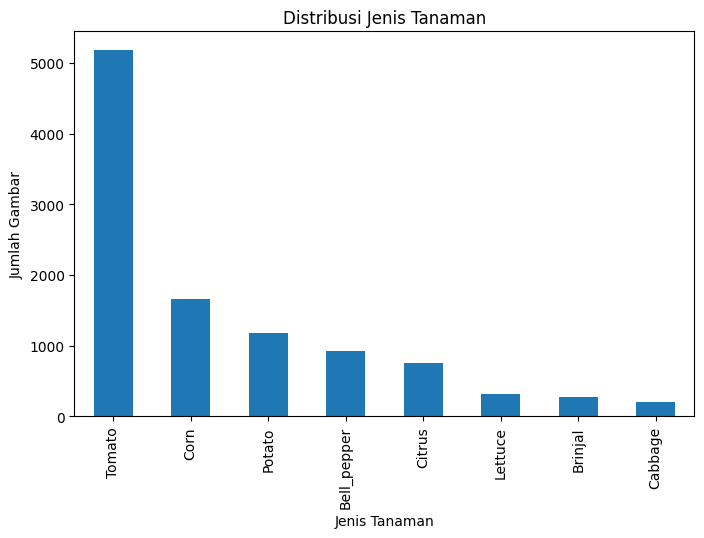

In [45]:
plt.figure(figsize=(8,5))

train_df["plant"].value_counts().plot(
    kind="bar"
)

plt.title("Distribusi Jenis Tanaman")
plt.xlabel("Jenis Tanaman")
plt.ylabel("Jumlah Gambar")

plt.show()

### Distribusi Jenis Penyakit

In [46]:
train_df["disease"].value_counts()

,count
disease,
Healthy,1767
Yellow_Leaf_Curl_Virus,978
Late_blight,974
Bacterial_spot,970
Early_blight,871
greening,695
Septoria_leaf_spot,508
Spider_mites,479
Target_Spot,458


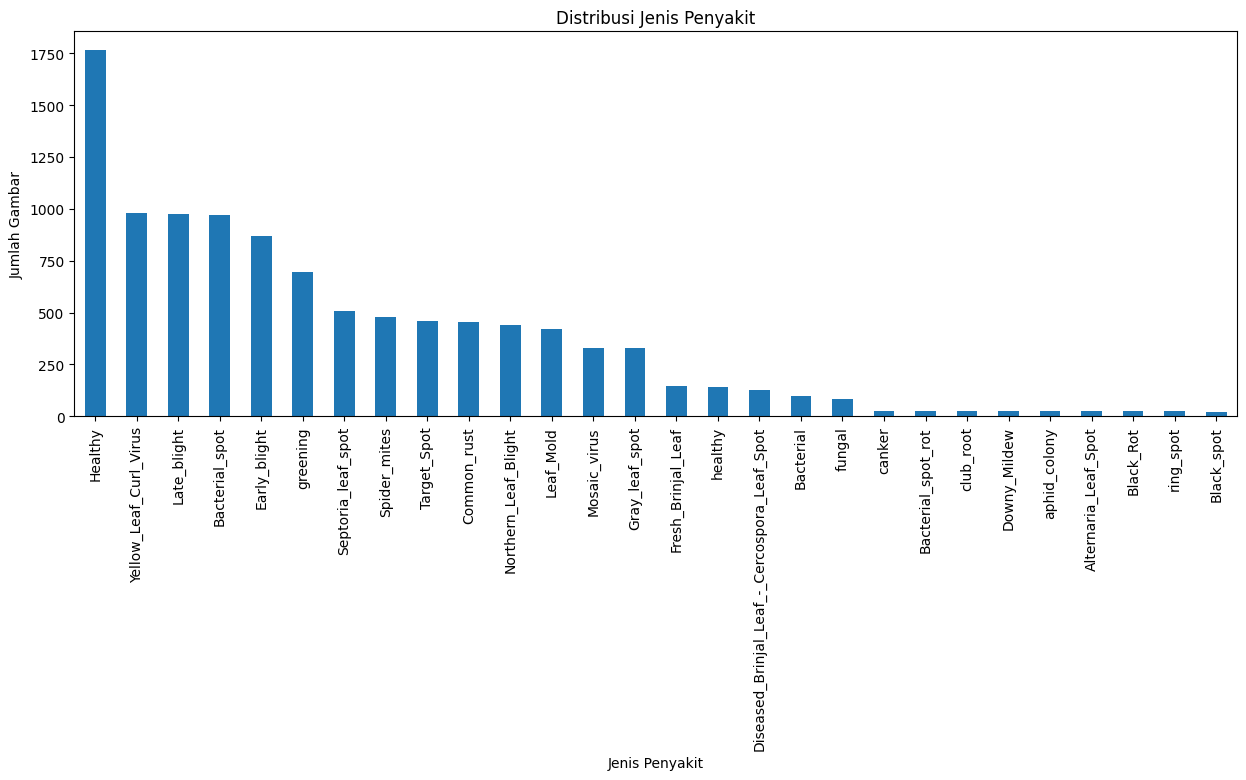

In [47]:
plt.figure(figsize=(15,5))

train_df["disease"].value_counts().plot(
    kind="bar"
)

plt.title("Distribusi Jenis Penyakit")
plt.xlabel("Jenis Penyakit")
plt.ylabel("Jumlah Gambar")

plt.xticks(rotation=90)

plt.show()

### Analisis Ukuran Citra

In [48]:
sample_path = train_df[
    "image_path"
].iloc[0]

img = cv2.imread(
    sample_path
)

print(
    "Ukuran citra:",
    img.shape
)

Ukuran citra: (256, 256, 3)


In [49]:
for i in range(5):

    img_path = train_df[
        "image_path"
    ].iloc[i]

    img = cv2.imread(
        img_path
    )

    print(
        f"Gambar {i+1}:",
        img.shape
    )

Gambar 1: (256, 256, 3)
Gambar 2: (256, 256, 3)
Gambar 3: (256, 256, 3)
Gambar 4: (256, 256, 3)
Gambar 5: (256, 256, 3)


### Distribusi Label Multi-Level

#### Jumlah Tanaman

In [50]:
print(
    train_df["plant"]
    .value_counts()
)

plant
Tomato         5188
Corn           1657
Potato         1178
Bell_pepper     928
Citrus          750
Lettuce         324
Brinjal         275
Cabbage         200
Name: count, dtype: int64


#### Jumlah Penyakit

In [51]:
print(
    train_df["disease"]
    .value_counts()
)

disease
Healthy                                         1767
Yellow_Leaf_Curl_Virus                           978
Late_blight                                      974
Bacterial_spot                                   970
Early_blight                                     871
greening                                         695
Septoria_leaf_spot                               508
Spider_mites                                     479
Target_Spot                                      458
Common_rust                                      457
Northern_Leaf_Blight                             441
Leaf_Mold                                        421
Mosaic_virus                                     330
Gray_leaf_spot                                   327
Fresh_Brinjal_Leaf                               146
healthy                                          143
Diseased_Brinjal_Leaf_-_Cercospora_Leaf_Spot     129
Bacterial                                         97
fungal                                

# Data Generator

In [52]:
import tensorflow as tf

### Menentukan Ukuran Input dan Batch Size

In [53]:
IMG_SIZE = 128

BATCH_SIZE = 32

### Fungsi Membaca Gambar

In [54]:
def load_image(image_path):

    image = tf.io.read_file(
        image_path
    )

    image = tf.image.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.resize(
        image,
        (IMG_SIZE, IMG_SIZE)
    )

    image = image / 255.0

    return image

### Membuat Dataset Training

In [55]:
train_dataset = tf.data.Dataset.from_tensor_slices(

    (

        train_df["image_path"].values,

        {

            "plant_output":
            train_df["plant_label"].values,

            "disease_output":
            train_df["disease_label"].values

        }

    )

)

#### Preprocessing Dataset Training

In [56]:
def process_train(
    image_path,
    labels
):

    image = load_image(
        image_path
    )

    return image, labels

In [57]:
train_dataset = train_dataset.map(
    process_train,
    num_parallel_calls=tf.data.AUTOTUNE
)

#### Batch Training

In [58]:
train_dataset = train_dataset.batch(
    BATCH_SIZE
)

#### Prefetch Training

In [59]:
train_dataset = train_dataset.prefetch(
    tf.data.AUTOTUNE
)

### Membuat Dataset Validation

In [60]:
val_dataset = tf.data.Dataset.from_tensor_slices(

    (

        val_df["image_path"].values,

        {

            "plant_output":
            val_df["plant_label"].values,

            "disease_output":
            val_df["disease_label"].values

        }

    )

)

#### Preprocessing Validation

In [61]:
def process_val(
    image_path,
    labels
):

    image = load_image(
        image_path
    )

    return image, labels

In [62]:
val_dataset = val_dataset.map(
    process_val,
    num_parallel_calls=tf.data.AUTOTUNE
)

In [63]:
val_dataset = val_dataset.batch(
    BATCH_SIZE
)

In [64]:
val_dataset = val_dataset.prefetch(
    tf.data.AUTOTUNE
)

### Membuat Dataset Testing

In [65]:
test_dataset = tf.data.Dataset.from_tensor_slices(

    (

        test_df["image_path"].values,

        {

            "plant_output":
            test_df["plant_label"].values,

            "disease_output":
            test_df["disease_label"].values

        }

    )

)

#### Preprocessing Testing

In [66]:
def process_test(
    image_path,
    labels
):

    image = load_image(
        image_path
    )

    return image, labels

In [67]:
test_dataset = test_dataset.map(
    process_test,
    num_parallel_calls=tf.data.AUTOTUNE
)

In [68]:
test_dataset = test_dataset.batch(
    BATCH_SIZE
)

In [69]:
test_dataset = test_dataset.prefetch(
    tf.data.AUTOTUNE
)

### Mengecek Dataset

In [70]:
for images, labels in train_dataset.take(1):

    print(
        "Shape Image :",
        images.shape
    )

    print(
        "Plant Label :",
        labels["plant_output"].shape
    )

    print(
        "Disease Label :",
        labels["disease_output"].shape
    )

Shape Image : (32, 128, 128, 3)
Plant Label : (32,)
Disease Label : (32,)


# Model CNN

In [71]:
from tensorflow.keras.applications import MobileNetV2

from tensorflow.keras.models import Model

from tensorflow.keras.layers import Input
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import GlobalAveragePooling2D

from tensorflow.keras.callbacks import EarlyStopping

### Membangun Model CNN

#### Input Layer

In [72]:
input_layer = Input(
    shape=(128,128,3)
)

base_model = MobileNetV2(

    weights='imagenet',

    include_top=False,

    input_tensor=input_layer

)

# Freeze seluruh layer MobileNet

base_model.trainable = False

x = base_model.output

x = GlobalAveragePooling2D()(x)

x = Dense(
    256,
    activation='relu'
)(x)

x = Dropout(0.5)(x)

# Output Jenis Tanaman

plant_output = Dense(

    NUM_PLANTS,

    activation='softmax',

    name='plant_output'

)(x)

# Output Jenis Penyakit

disease_output = Dense(

    NUM_DISEASES,

    activation='softmax',

    name='disease_output'

)(x)

cnn_model = Model(

    inputs=input_layer,

    outputs=[
        plant_output,
        disease_output
    ]

)

/tmp/ipykernel_1632/1220324474.py:5: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


### Menampilkan Struktur Model

In [73]:
cnn_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 64, 64,    │        864 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 64, 64,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 64, 64,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 64, 64,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 64, 64,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 64, 64,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 65, 65,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 32, 32,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 32, 32,    │      2,304 │ block_1_depthwis

 Total params: 2,595,172 (9.90 MB)

 Trainable params: 337,188 (1.29 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Training Model CNN

#### Menentukan Aturan Training

In [74]:
cnn_model.compile(

    optimizer='adam',

    loss={

        'plant_output':
        'sparse_categorical_crossentropy',

        'disease_output':
        'sparse_categorical_crossentropy'

    },

    metrics={

        'plant_output':['accuracy'],

        'disease_output':['accuracy']

    }

)

#### Training Model

In [75]:
from tensorflow.keras.callbacks import EarlyStopping

In [76]:
early_stop = EarlyStopping(

    monitor='val_loss',

    patience=15,

    restore_best_weights=True,

    verbose=1

)

In [77]:
history = cnn_model.fit(

    train_dataset,

    validation_data=val_dataset,

    epochs=50,

    callbacks=[early_stop]

)

Epoch 1/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 58s 122ms/step - disease_output_accuracy: 0.6070 - disease_output_loss: 1.3021 - loss: 1.6755 - plant_output_accuracy: 0.8857 - plant_output_loss: 0.3712 - val_disease_output_accuracy: 0.7698 - val_disease_output_loss: 0.6875 - val_loss: 0.8501 - val_plant_output_accuracy: 0.9507 - val_plant_output_loss: 0.1557
Epoch 2/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 45s 49ms/step - disease_output_accuracy: 0.7561 - disease_output_loss: 0.7534 - loss: 0.9227 - plant_output_accuracy: 0.9439 - plant_output_loss: 0.1706 - val_disease_output_accuracy: 0.8036 - val_disease_output_loss: 0.5809 - val_loss: 0.7130 - val_plant_output_accuracy: 0.9600 - val_plant_output_loss: 0.1262
Epoch 3/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - disease_output_accuracy: 0.8033 - disease_output_loss: 0.5925 - loss: 0.7214 - plant_output_accuracy: 0.9575 - plant_output_loss: 0.1274 - val_disease_output_accuracy: 0.8347 - val_disease_output_loss: 0.4906 - val_loss: 0.6071 - val_plant

In [78]:
# Save Model

cnn_model.save(
    "cnn_multilevel.keras"
)

print(
    "Model berhasil disimpan"
)

Model berhasil disimpan


In [79]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
cnn_model.save(
    "/content/drive/MyDrive/SEMESTER 4/cnn_multilevel.keras"
)

In [ ]:
import os

print(
    os.listdir("/content/drive/MyDrive/SEMESTER 4")
)

### Evaluasi Data Testing

In [80]:
results = cnn_model.evaluate(
    test_dataset
)

print(results)

71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - disease_output_accuracy: 0.8720 - disease_output_loss: 0.4003 - loss: 0.4936 - plant_output_accuracy: 0.9720 - plant_output_loss: 0.1001
[0.49359989166259766, 0.10012607276439667, 0.4002656042575836, 0.871999979019165, 0.972000002861023]


### Grafik Akurasi Tanaman

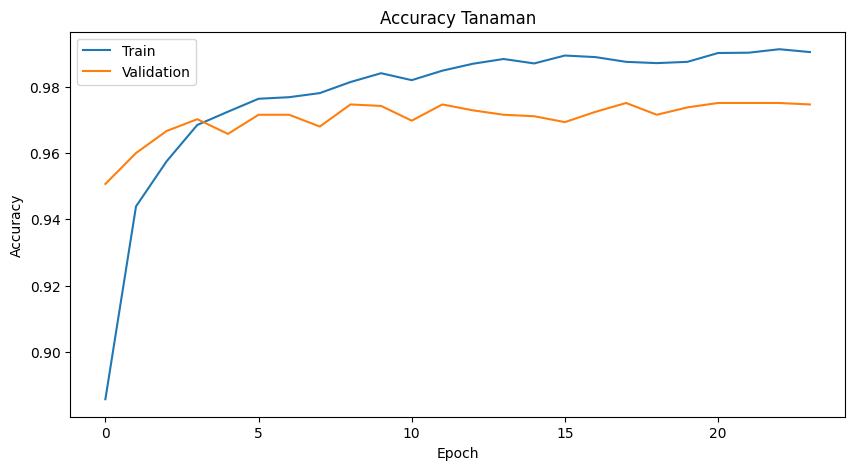

In [81]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(
    history.history[
        'plant_output_accuracy'
    ]
)

plt.plot(
    history.history[
        'val_plant_output_accuracy'
    ]
)

plt.title(
    'Accuracy Tanaman'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend(
    ['Train','Validation']
)

plt.show()

### Grafik Akurasi Penyakit

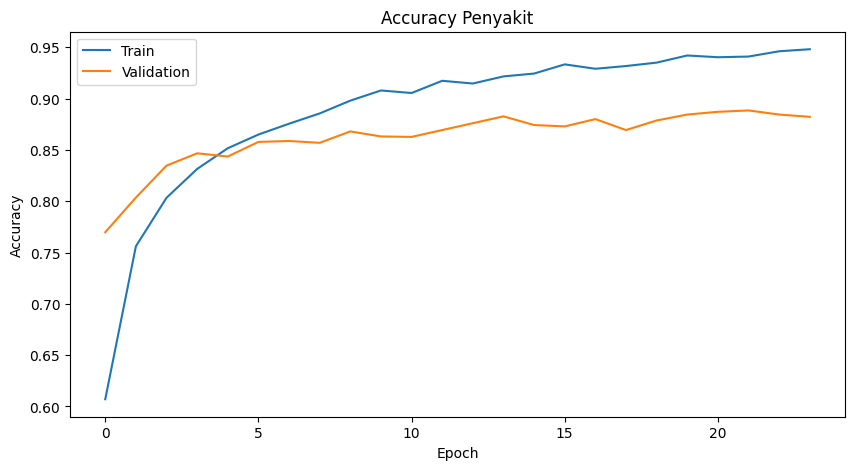

In [82]:
plt.figure(figsize=(10,5))

plt.plot(
    history.history[
        'disease_output_accuracy'
    ]
)

plt.plot(
    history.history[
        'val_disease_output_accuracy'
    ]
)

plt.title(
    'Accuracy Penyakit'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend(
    ['Train','Validation']
)

plt.show()

### Prediksi

In [83]:
predictions = cnn_model.predict(
    test_dataset
)

plant_pred = np.argmax(
    predictions[0],
    axis=1
)

disease_pred = np.argmax(
    predictions[1],
    axis=1
)

plant_true = test_df[
    "plant_label"
].values

disease_true = test_df[
    "disease_label"
].values

71/71 ━━━━━━━━━━━━━━━━━━━━ 12s 91ms/step


### Grafik Loss

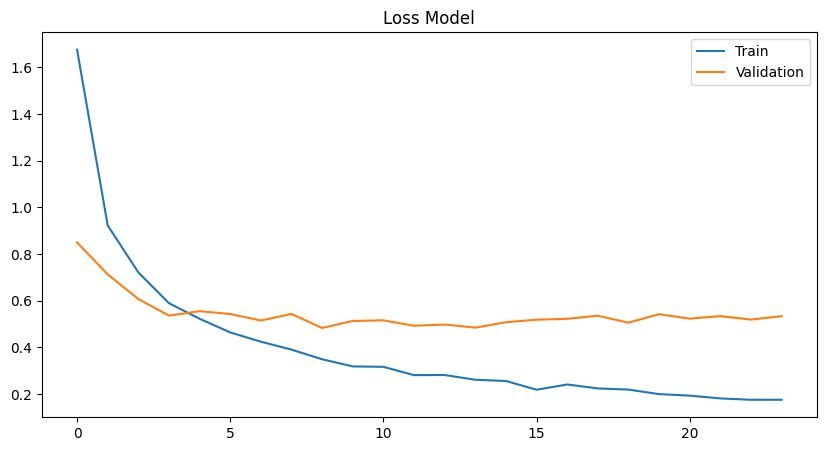

In [84]:
plt.figure(figsize=(10,5))

plt.plot(
    history.history['loss']
)

plt.plot(
    history.history['val_loss']
)

plt.title(
    'Loss Model'
)

plt.legend(
    ['Train','Validation']
)

plt.show()

In [85]:
print(history.history['plant_output_accuracy'][-1])
print(history.history['val_plant_output_accuracy'][-1])

print(history.history['disease_output_accuracy'][-1])
print(history.history['val_disease_output_accuracy'][-1])

0.9904761910438538
0.9746666550636292
0.9480952620506287
0.8822222352027893


In [86]:
print(sorted(train_df["disease"].unique()))

['Alternaria_Leaf_Spot', 'Bacterial', 'Bacterial_spot', 'Bacterial_spot_rot', 'Black_Rot', 'Black_spot', 'Common_rust', 'Diseased_Brinjal_Leaf_-_Cercospora_Leaf_Spot', 'Downy_Mildew', 'Early_blight', 'Fresh_Brinjal_Leaf', 'Gray_leaf_spot', 'Healthy', 'Late_blight', 'Leaf_Mold', 'Mosaic_virus', 'Northern_Leaf_Blight', 'Septoria_leaf_spot', 'Spider_mites', 'Target_Spot', 'Yellow_Leaf_Curl_Virus', 'aphid_colony', 'canker', 'club_root', 'fungal', 'greening', 'healthy', 'ring_spot']


### Confusion Matrix Tanaman

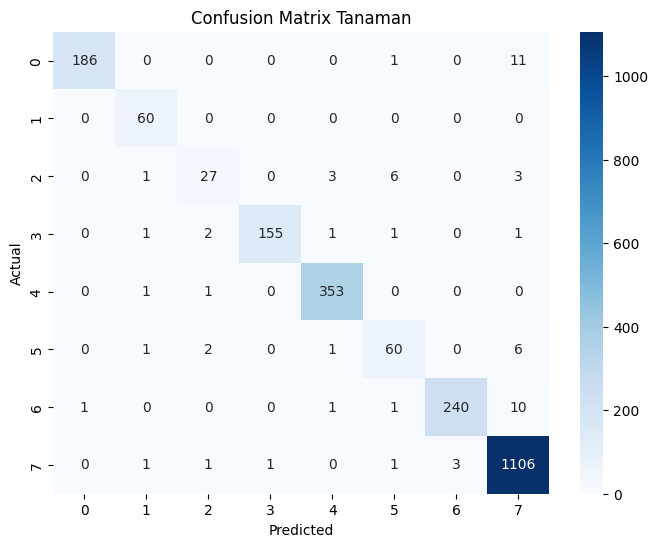

In [87]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm_plant = confusion_matrix(
    plant_true,
    plant_pred
)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm_plant,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title(
    "Confusion Matrix Tanaman"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

### Classification Report Tanaman

In [96]:
from sklearn.metrics import classification_report

print(
    classification_report(
       plant_true,
       plant_pred
    )
)

              precision    recall  f1-score   support

           0       0.99      0.94      0.97       198
           1       0.92      1.00      0.96        60
           2       0.82      0.68      0.74        40
           3       0.99      0.96      0.98       161
           4       0.98      0.99      0.99       355
           5       0.86      0.86      0.86        70
           6       0.99      0.95      0.97       253
           7       0.97      0.99      0.98      1113

    accuracy                           0.97      2250
   macro avg       0.94      0.92      0.93      2250
weighted avg       0.97      0.97      0.97      2250



### Confusion Matrix Penyakit

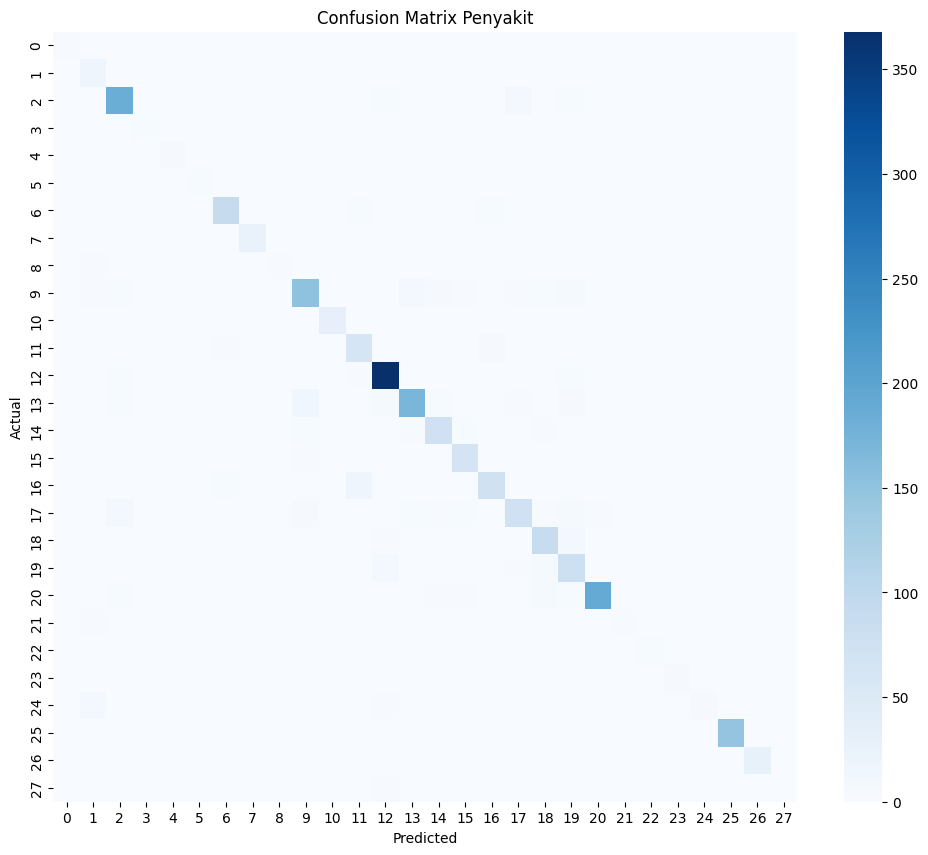

In [90]:
cm_disease = confusion_matrix(
    disease_true,
    disease_pred
)

plt.figure(figsize=(12,10))

sns.heatmap(
    cm_disease,
    cmap='Blues'
)

plt.title(
    "Confusion Matrix Penyakit"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

### Classification Report Penyakit

In [97]:
print(

    classification_report(

        disease_true,

        disease_pred,

        target_names=
        disease_encoder.classes_

    )

)

                                              precision    recall  f1-score   support

                        Alternaria_Leaf_Spot       1.00      0.40      0.57         5
                                   Bacterial       0.49      0.81      0.61        21
                              Bacterial_spot       0.88      0.89      0.88       208
                          Bacterial_spot_rot       1.00      0.60      0.75         5
                                   Black_Rot       1.00      1.00      1.00         5
                                  Black_spot       0.75      0.60      0.67         5
                                 Common_rust       0.94      0.93      0.93        98
Diseased_Brinjal_Leaf_-_Cercospora_Leaf_Spot       0.90      0.96      0.93        28
                                Downy_Mildew       0.67      0.40      0.50         5
                                Early_blight       0.84      0.81      0.83       187
                          Fresh_Brinjal_Leaf       0.

# Model CNN+SVM

## Import Library Tambahan

In [92]:
# Import untuk CNN+SVM
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D

import joblib

print("Import berhasil!")
print(f"TensorFlow : {tf.__version__}")


Import berhasil!
TensorFlow : 2.20.0


## Persiapan Data untuk ResNet50


In [93]:
RESNET_IMG_SIZE = 224
RESNET_BATCH    = 32

def load_image_resnet(image_path):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (RESNET_IMG_SIZE, RESNET_IMG_SIZE))
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)
    return image

def make_image_dataset(df):
    ds = tf.data.Dataset.from_tensor_slices(df["image_path"].values)
    ds = ds.map(load_image_resnet, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(RESNET_BATCH).prefetch(tf.data.AUTOTUNE)
    return ds

img_ds_train = make_image_dataset(train_df)
img_ds_val   = make_image_dataset(val_df)
img_ds_test  = make_image_dataset(test_df)

print("Dataset gambar berhasil dibuat:")
print(f"Train  : {len(train_df):>6,} gambar → {len(img_ds_train)} batch")
print(f"Val    : {len(val_df):>6,} gambar → {len(img_ds_val)} batch")
print(f"Test   : {len(test_df):>6,} gambar → {len(img_ds_test)} batch")


Dataset gambar berhasil dibuat:
Train  : 10,500 gambar → 329 batch
Val    :  2,250 gambar → 71 batch
Test   :  2,250 gambar → 71 batch


## Membangun Feature Extractor ResNet50


In [94]:
resnet_base = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(RESNET_IMG_SIZE, RESNET_IMG_SIZE, 3)
)

resnet_base.trainable = False

feat_output = GlobalAveragePooling2D(name='feature_vector')(resnet_base.output)

feature_extractor = Model(
    inputs=resnet_base.input,
    outputs=feat_output,
    name='ResNet50_FeatureExtractor'
)

# Info model
total_params      = feature_extractor.count_params()
trainable_params  = sum(np.prod(v.shape) for v in feature_extractor.trainable_variables)
frozen_params     = total_params - trainable_params

print("="*50)
print(f"Model   : {feature_extractor.name}")
print(f"Input   : {feature_extractor.input_shape}")
print(f"Output  : {feature_extractor.output_shape}  ← fitur 2048-dim")
print(f"Params  : {total_params:,} total")
print(f"Frozen  : {frozen_params:,}  (tidak dilatih)")
print(f"Trainable: {trainable_params:,}")
print("="*50)


Model   : ResNet50_FeatureExtractor
Input   : (None, 224, 224, 3)
Output  : (None, 2048)  ← fitur 2048-dim
Params  : 23,587,712 total
Frozen  : 23,587,712  (tidak dilatih)
Trainable: 0


## Ekstraksi Fitur ResNet50

In [95]:
def extract_features(image_dataset, model, split_name=""):
    """Ekstrak fitur CNN dari seluruh gambar dalam dataset."""
    all_features = []

    for batch in tqdm(image_dataset, desc=f"Ekstraksi [{split_name}]", unit="batch"):
        feats = model(batch, training=False).numpy()
        all_features.append(feats)

    return np.vstack(all_features)

print("Memulai ekstraksi fitur ResNet50...")
print("(Proses ini memakan waktu sesuai ukuran dataset)\n")

X_train = extract_features(img_ds_train, feature_extractor, "Train")
X_val   = extract_features(img_ds_val,   feature_extractor, "Val")
X_test  = extract_features(img_ds_test,  feature_extractor, "Test")

print(f"\nEkstraksi selesai!")
print(f"X_train shape : {X_train.shape}")
print(f"X_val   shape : {X_val.shape}")
print(f"X_test  shape : {X_test.shape}")


Memulai ekstraksi fitur ResNet50...
(Proses ini memakan waktu sesuai ukuran dataset)



Ekstraksi [Test]: 100%|██████████| 71/71 [00:40<00:00,  1.73batch/s]


Ekstraksi selesai!
X_train shape : (10500, 2048)
X_val   shape : (2250, 2048)
X_test  shape : (2250, 2048)


In [56]:
y_plant_train   = train_df["plant_label"].values
y_disease_train = train_df["disease_label"].values

y_plant_val     = val_df["plant_label"].values
y_disease_val   = val_df["disease_label"].values

y_plant_test    = test_df["plant_label"].values
y_disease_test  = test_df["disease_label"].values

X_svm_train        = np.vstack([X_train, X_val])
y_plant_svm_train  = np.concatenate([y_plant_train, y_plant_val])
y_disease_svm_train = np.concatenate([y_disease_train, y_disease_val])

print("Data SVM siap:")
print(f"Train (train+val) : {X_svm_train.shape[0]:,} sampel × {X_svm_train.shape[1]} fitur")
print(f"Test              : {X_test.shape[0]:,} sampel × {X_test.shape[1]} fitur")
print(f"Jumlah plant kelas  : {len(np.unique(y_plant_svm_train))}")
print(f"Jumlah disease kelas: {len(np.unique(y_disease_svm_train))}")


Data SVM siap:
  Train (train+val) : 12,750 sampel × 2048 fitur
  Test              : 2,250 sampel × 2048 fitur
  Jumlah plant kelas  : 8
  Jumlah disease kelas: 28


## Training SVM — Klasifikasi Tanaman (Plant)


In [57]:
from tqdm import tqdm

print("Training SVM Plant...")
print(f"  Kelas tanaman : {list(plant_encoder.classes_)}")
print(f"  Jumlah kelas  : {NUM_PLANTS}")
print()

svm_plant = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(
        kernel='rbf',
        C=50,
        gamma='scale',
        probability=True,
        decision_function_shape='ovr',
        random_state=42
    ))
])

print("Training SVM Plant...")

for _ in tqdm(range(1), desc="Training Progress"):
  svm_plant.fit(X_svm_train, y_plant_svm_train)

print("SVM Plant berhasil dilatih!")


Training SVM Plant...
  Kelas tanaman : ['Bell_pepper', 'Brinjal', 'Cabbage', 'Citrus', 'Corn', 'Lettuce', 'Potato', 'Tomato']
  Jumlah kelas  : 8

Training SVM Plant...


Training Progress: 100%|██████████| 1/1 [06:39<00:00, 399.71s/it]

✅ SVM Plant berhasil dilatih!


In [ ]:
# Save Model

svm_plant.save(
    "cnn_multilevel.keras"
)

print(
    "Model berhasil disimpan"
)

## Training SVM — Klasifikasi Penyakit (Disease)


In [58]:
print("Training SVM Disease...")
print(f"  Jumlah kelas penyakit : {NUM_DISEASES}")
print()

svm_disease = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(
        kernel='rbf',
        C=50,
        gamma='scale',
        probability=True,
        decision_function_shape='ovr',
        random_state=42
    ))
])

for _ in tqdm(range(1), desc="Training Progress"):
  svm_disease.fit(X_svm_train, y_disease_svm_train)

print("SVM Disease berhasil dilatih!")


Training SVM Disease...
  Jumlah kelas penyakit : 28



Training Progress: 100%|██████████| 1/1 [08:58<00:00, 538.78s/it]

✅ SVM Disease berhasil dilatih!


## Evaluasi CNN+SVM — Klasifikasi Tanaman (Plant)

In [59]:
# Prediksi Plant
y_pred_plant = svm_plant.predict(X_test)

svm_plant_acc = accuracy_score(y_plant_test, y_pred_plant)
print(f"  Accuracy SVM Plant  : {svm_plant_acc:.4f}  ({svm_plant_acc*100:.2f}%)")


  Accuracy SVM Plant  : 0.9840  (98.40%)


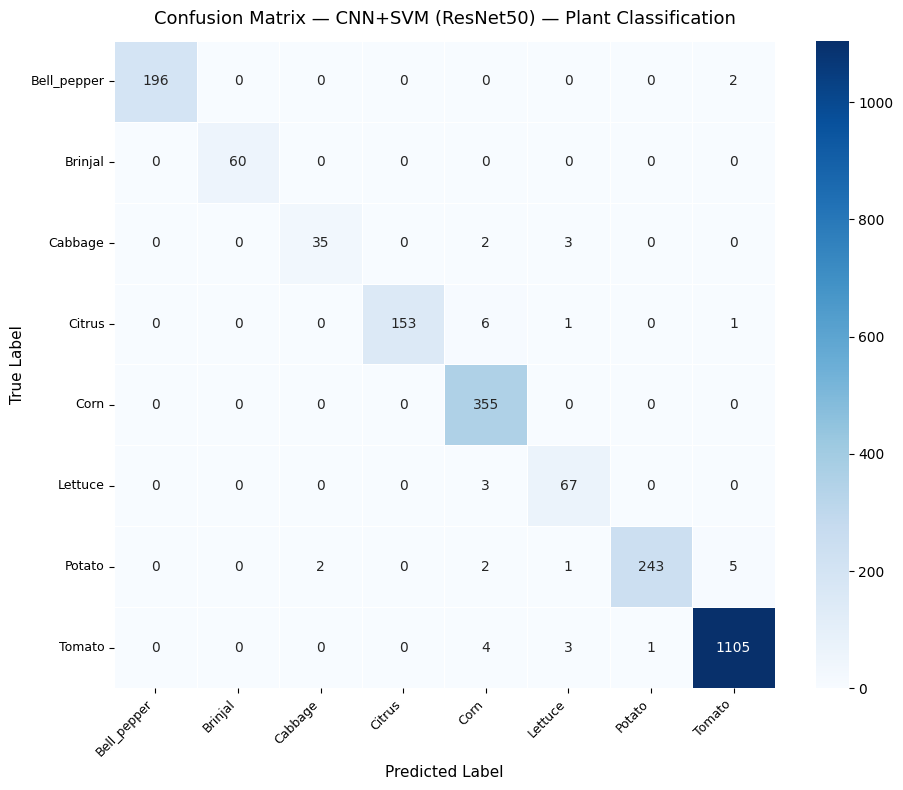

In [60]:
# Confusion Matrix — Plant
cm_plant = confusion_matrix(y_plant_test, y_pred_plant)
plant_class_names = list(plant_encoder.classes_)

plt.figure(figsize=(max(8, NUM_PLANTS*1.2), max(6, NUM_PLANTS)))
sns.heatmap(
    cm_plant,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=plant_class_names,
    yticklabels=plant_class_names,
    linewidths=0.5
)
plt.title("Confusion Matrix — CNN+SVM (ResNet50) — Plant Classification", fontsize=13, pad=12)
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("True Label", fontsize=11)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()


In [61]:
print("Classification Report — CNN+SVM ResNet50 — Plant")
print("="*60)
print(classification_report(
    y_plant_test,
    y_pred_plant,
    target_names=plant_class_names
))


Classification Report — CNN+SVM ResNet50 — Plant
              precision    recall  f1-score   support

 Bell_pepper       1.00      0.99      0.99       198
     Brinjal       1.00      1.00      1.00        60
     Cabbage       0.95      0.88      0.91        40
      Citrus       1.00      0.95      0.97       161
        Corn       0.95      1.00      0.98       355
     Lettuce       0.89      0.96      0.92        70
      Potato       1.00      0.96      0.98       253
      Tomato       0.99      0.99      0.99      1113

    accuracy                           0.98      2250
   macro avg       0.97      0.97      0.97      2250
weighted avg       0.98      0.98      0.98      2250



## Evaluasi CNN+SVM — Klasifikasi Penyakit (Disease)

In [62]:
y_pred_disease = svm_disease.predict(X_test)

svm_disease_acc = accuracy_score(y_disease_test, y_pred_disease)
print("="*50)
print(f"  Accuracy SVM Disease: {svm_disease_acc:.4f}  ({svm_disease_acc*100:.2f}%)")
print("="*50)


  Accuracy SVM Disease: 0.9471  (94.71%)


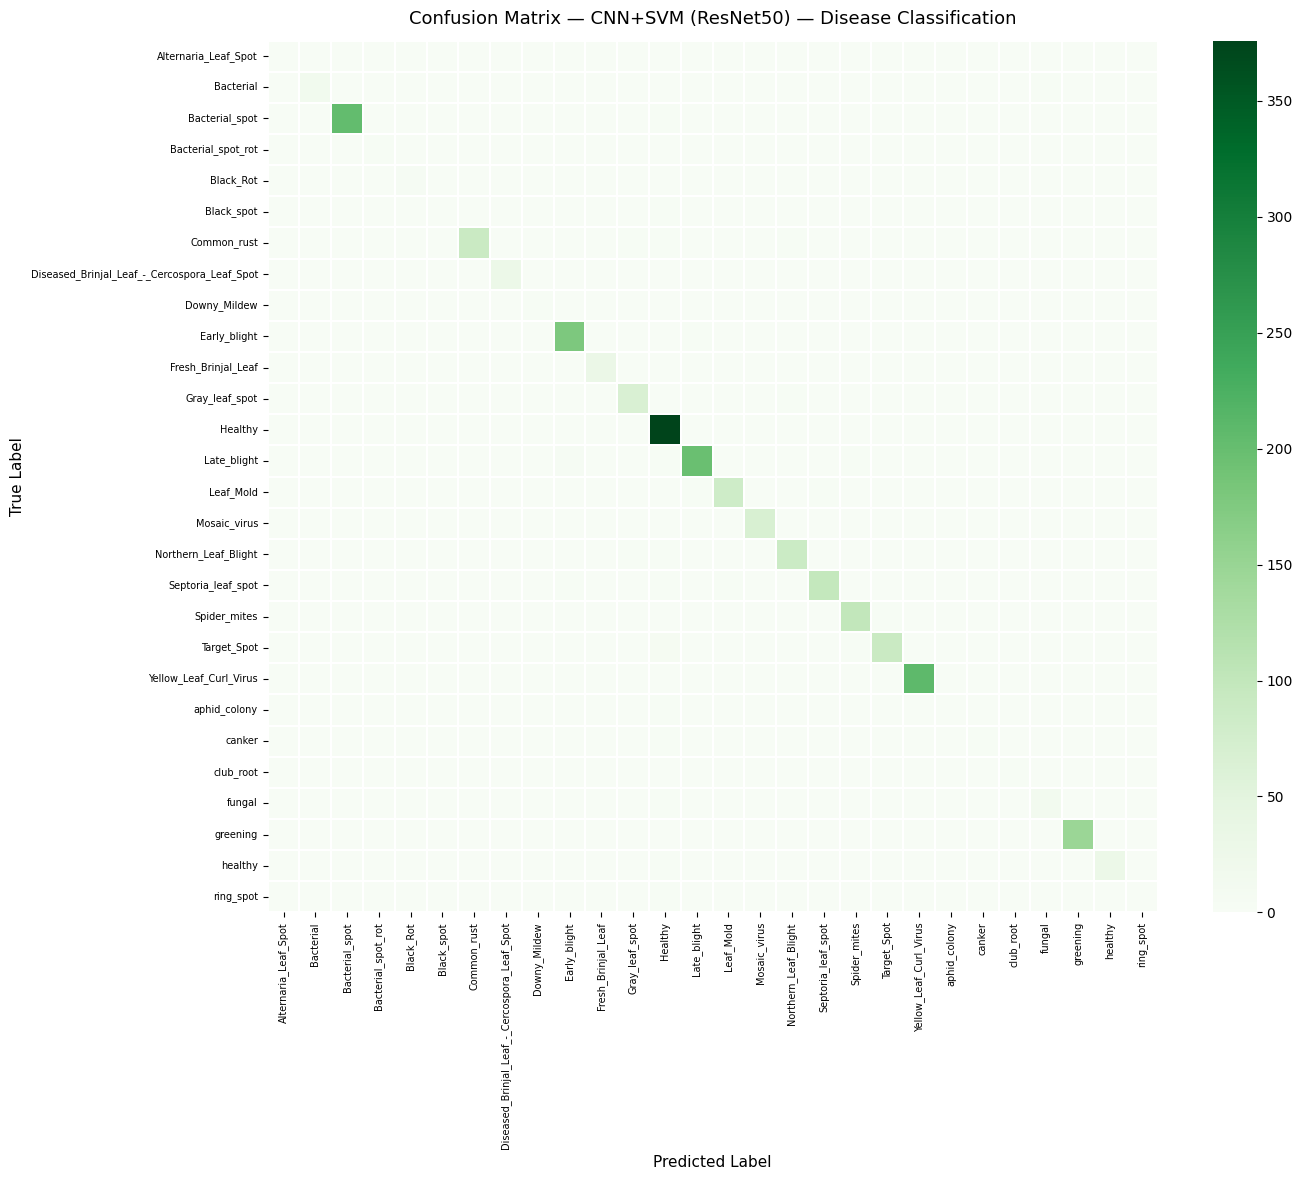

In [63]:
cm_disease = confusion_matrix(y_disease_test, y_pred_disease)
disease_class_names = list(disease_encoder.classes_)

fig_size = max(14, NUM_DISEASES * 0.5)
plt.figure(figsize=(fig_size, fig_size * 0.85))
sns.heatmap(
    cm_disease,
    annot=(NUM_DISEASES <= 20),
    fmt='d',
    cmap='Greens',
    xticklabels=disease_class_names,
    yticklabels=disease_class_names,
    linewidths=0.3
)
plt.title("Confusion Matrix — CNN+SVM (ResNet50) — Disease Classification", fontsize=13, pad=12)
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("True Label", fontsize=11)
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
plt.show()


In [64]:
print("Classification Report — CNN+SVM ResNet50 — Disease")
print("="*60)
print(classification_report(
    y_disease_test,
    y_pred_disease,
    target_names=disease_class_names
))


Classification Report — CNN+SVM ResNet50 — Disease
                                              precision    recall  f1-score   support

                        Alternaria_Leaf_Spot       1.00      0.20      0.33         5
                                   Bacterial       0.73      0.76      0.74        21
                              Bacterial_spot       0.99      0.98      0.98       208
                          Bacterial_spot_rot       1.00      0.80      0.89         5
                                   Black_Rot       1.00      1.00      1.00         5
                                  Black_spot       1.00      0.20      0.33         5
                                 Common_rust       1.00      0.92      0.96        98
Diseased_Brinjal_Leaf_-_Cercospora_Leaf_Spot       1.00      1.00      1.00        28
                                Downy_Mildew       1.00      0.60      0.75         5
                                Early_blight       0.96      0.95      0.95       187
  

## Perbandingan Akurasi: CNN Biasa vs CNN+SVM (ResNet50)


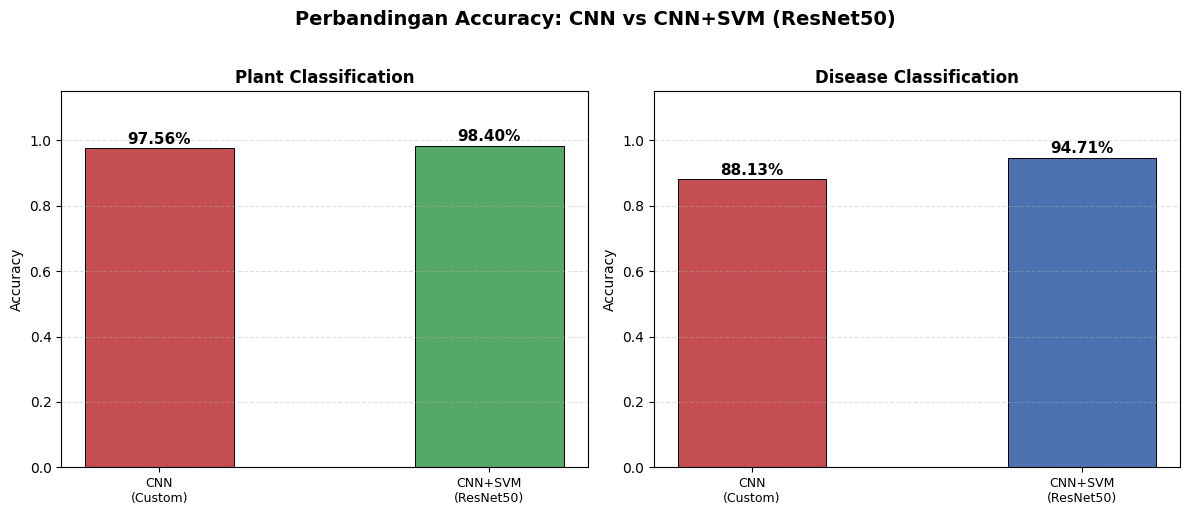


Ringkasan Akurasi:
  SVM Plant   (ResNet50) : 98.40%
  SVM Disease (ResNet50) : 94.71%
  CNN Plant   (Custom)   : 97.56%
  CNN Disease (Custom)   : 88.13%


In [99]:
try:
    cnn_plant_acc   = history.history.get(
        'val_plant_output_accuracy',
        history.history.get('plant_output_accuracy', [None])
    )[-1]

    cnn_disease_acc = history.history.get(
        'val_disease_output_accuracy',
        history.history.get('disease_output_accuracy', [None])
    )[-1]

    has_cnn = (cnn_plant_acc is not None and cnn_disease_acc is not None)

except Exception:
    has_cnn = False

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

tasks  = ['Plant Classification', 'Disease Classification']
svm_accs = [svm_plant_acc, svm_disease_acc]
colors_svm = ['#55A868', '#4C72B0']

for ax, task, svm_acc, color in zip(axes, tasks, svm_accs, colors_svm):

    bars_data  = {'CNN+SVM\n(ResNet50)': svm_acc}
    bar_colors = [color]

    if has_cnn:
        cnn_acc = cnn_plant_acc if 'Plant' in task else cnn_disease_acc
        if cnn_acc is not None:
            bars_data = {'CNN\n(Custom)': cnn_acc, **bars_data}
            bar_colors = ['#C44E52'] + bar_colors

    bars = ax.bar(
        list(bars_data.keys()),
        list(bars_data.values()),
        color=bar_colors,
        width=0.45,
        edgecolor='black',
        linewidth=0.7
    )

    for bar, val in zip(bars, bars_data.values()):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.005,
            f'{val*100:.2f}%',
            ha='center', va='bottom',
            fontsize=11, fontweight='bold'
        )

    ax.set_ylim(0, 1.15)
    ax.set_title(task, fontsize=12, fontweight='bold')
    ax.set_ylabel("Accuracy", fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.tick_params(axis='x', labelsize=9)

fig.suptitle(
    "Perbandingan Accuracy: CNN vs CNN+SVM (ResNet50)",
    fontsize=14, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.show()

print("\nRingkasan Akurasi:")
print(f"  SVM Plant   (ResNet50) : {svm_plant_acc*100:.2f}%")
print(f"  SVM Disease (ResNet50) : {svm_disease_acc*100:.2f}%")
if has_cnn and cnn_plant_acc and cnn_disease_acc:
    print(f"  CNN Plant   (Custom)   : {cnn_plant_acc*100:.2f}%")
    print(f"  CNN Disease (Custom)   : {cnn_disease_acc*100:.2f}%")


In [103]:
comparison = pd.DataFrame({

    "Metode":[
        "CNN",
        "CNN+SVM"
    ],

    "Akurasi Tanaman":[
        cnn_plant_acc,
        svm_plant_acc
    ],

    "Akurasi Penyakit":[
        cnn_disease_acc,
        svm_disease_acc
    ]

})

comparison

,Metode,Akurasi Tanaman,Akurasi Penyakit
0,CNN,0.975556,0.881333
1,CNN+SVM,0.984000,0.947111


##Hasil Grafik Loss Accuracy

Menghitung Log Loss CNN+SVM (ResNet50)...
  Plant   → Train Loss : 0.0018  |  Test Loss : 0.0496
  Disease → Train Loss : 0.0065  |  Test Loss : 0.1822


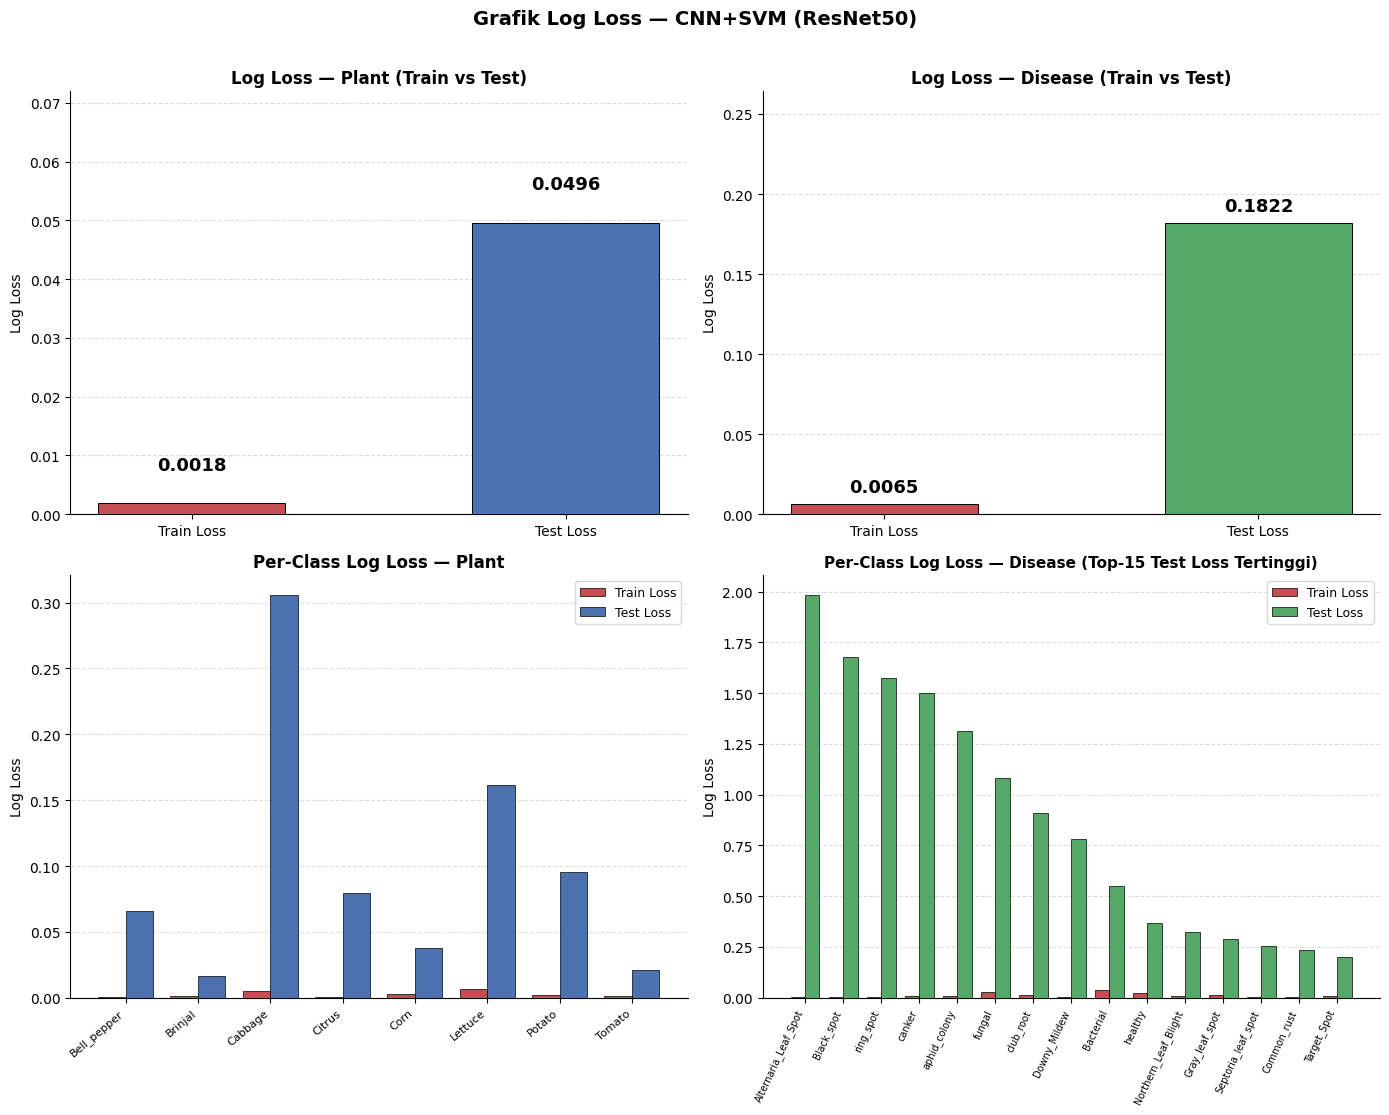


  Interpretasi Gap (Test Loss − Train Loss)
  Plant   : gap = +0.0478  → well-fitted (gap sangat kecil)
  Disease : gap = +0.1757  → sedikit overfit — masih wajar


In [66]:
from sklearn.metrics import log_loss
import matplotlib.pyplot as plt
import numpy as np

print("Menghitung Log Loss CNN+SVM (ResNet50)...")

prob_plant_train    = svm_plant.predict_proba(X_svm_train)
prob_plant_test     = svm_plant.predict_proba(X_test)
prob_disease_train  = svm_disease.predict_proba(X_svm_train)
prob_disease_test   = svm_disease.predict_proba(X_test)

ll_plant_train    = log_loss(y_plant_svm_train,  prob_plant_train)
ll_plant_test     = log_loss(y_plant_test,        prob_plant_test)
ll_disease_train  = log_loss(y_disease_svm_train, prob_disease_train)
ll_disease_test   = log_loss(y_disease_test,      prob_disease_test)

print(f"  Plant   → Train Loss : {ll_plant_train:.4f}  |  Test Loss : {ll_plant_test:.4f}")
print(f"  Disease → Train Loss : {ll_disease_train:.4f}  |  Test Loss : {ll_disease_test:.4f}")

def per_class_log_loss(y_true, y_proba):
    n_classes = y_proba.shape[1]
    losses    = np.zeros(n_classes)
    for c in range(n_classes):
        mask = (y_true == c)
        if mask.sum() == 0:
            continue
        p_correct  = np.clip(y_proba[mask, c], 1e-15, 1.0)
        losses[c]  = -np.mean(np.log(p_correct))
    return losses

plant_cls_loss_train    = per_class_log_loss(y_plant_svm_train,  prob_plant_train)
plant_cls_loss_test     = per_class_log_loss(y_plant_test,        prob_plant_test)
disease_cls_loss_train  = per_class_log_loss(y_disease_svm_train, prob_disease_train)
disease_cls_loss_test   = per_class_log_loss(y_disease_test,      prob_disease_test)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
BAR_W = 0.38

def style_ax(ax):
    ax.grid(axis='y', linestyle='--', alpha=0.4, zorder=0)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

ax = axes[0, 0]
vals_p  = [ll_plant_train, ll_plant_test]
colors1 = ['#C44E52', '#4C72B0']
bars    = ax.bar(['Train Loss', 'Test Loss'], vals_p,
                 color=colors1, width=0.5,
                 edgecolor='black', linewidth=0.7, zorder=3)
for bar, v in zip(bars, vals_p):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005,
            f'{v:.4f}', ha='center', va='bottom',
            fontsize=13, fontweight='bold')
ax.set_title('Log Loss — Plant (Train vs Test)',
             fontsize=12, fontweight='bold')
ax.set_ylabel('Log Loss', fontsize=10)
ax.set_ylim(0, max(vals_p) * 1.45)
style_ax(ax)

ax = axes[0, 1]
vals_d  = [ll_disease_train, ll_disease_test]
colors2 = ['#C44E52', '#55A868']
bars    = ax.bar(['Train Loss', 'Test Loss'], vals_d,
                 color=colors2, width=0.5,
                 edgecolor='black', linewidth=0.7, zorder=3)
for bar, v in zip(bars, vals_d):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005,
            f'{v:.4f}', ha='center', va='bottom',
            fontsize=13, fontweight='bold')
ax.set_title('Log Loss — Disease (Train vs Test)',
             fontsize=12, fontweight='bold')
ax.set_ylabel('Log Loss', fontsize=10)
ax.set_ylim(0, max(vals_d) * 1.45)
style_ax(ax)

ax      = axes[1, 0]
p_names = list(plant_encoder.classes_)
x_p     = np.arange(len(p_names))
ax.bar(x_p - BAR_W/2, plant_cls_loss_train, BAR_W,
       label='Train Loss', color='#C44E52',
       edgecolor='black', linewidth=0.5, zorder=3)
ax.bar(x_p + BAR_W/2, plant_cls_loss_test,  BAR_W,
       label='Test Loss',  color='#4C72B0',
       edgecolor='black', linewidth=0.5, zorder=3)
ax.set_xticks(x_p)
ax.set_xticklabels(p_names, rotation=40, ha='right', fontsize=8)
ax.set_title('Per-Class Log Loss — Plant',
             fontsize=12, fontweight='bold')
ax.set_ylabel('Log Loss', fontsize=10)
ax.legend(fontsize=9)
style_ax(ax)

ax        = axes[1, 1]
d_names   = list(disease_encoder.classes_)
sort_idx  = np.argsort(disease_cls_loss_test)[::-1][:15]
top_names = [d_names[i] for i in sort_idx]
top_tr    = disease_cls_loss_train[sort_idx]
top_te    = disease_cls_loss_test[sort_idx]
x_d       = np.arange(len(top_names))
ax.bar(x_d - BAR_W/2, top_tr, BAR_W,
       label='Train Loss', color='#C44E52',
       edgecolor='black', linewidth=0.5, zorder=3)
ax.bar(x_d + BAR_W/2, top_te, BAR_W,
       label='Test Loss',  color='#55A868',
       edgecolor='black', linewidth=0.5, zorder=3)
ax.set_xticks(x_d)
ax.set_xticklabels(top_names, rotation=65, ha='right', fontsize=7)
ax.set_title('Per-Class Log Loss — Disease (Top-15 Test Loss Tertinggi)',
             fontsize=11, fontweight='bold')
ax.set_ylabel('Log Loss', fontsize=10)
ax.legend(fontsize=9)
style_ax(ax)

fig.suptitle(
    'Grafik Log Loss — CNN+SVM (ResNet50)',
    fontsize=14, fontweight='bold', y=1.01
)
plt.tight_layout()
plt.show()

print()
print("=" * 55)
print("  Interpretasi Gap (Test Loss − Train Loss)")
print("=" * 55)
gap_p = ll_plant_test - ll_plant_train
gap_d = ll_disease_test - ll_disease_train

def interpret_gap(gap):
    if   abs(gap) < 0.05: return "well-fitted (gap sangat kecil)"
    elif abs(gap) < 0.20: return "sedikit overfit — masih wajar"
    else:                 return "indikasi overfitting — perlu regularisasi"

print(f"  Plant   : gap = {gap_p:+.4f}  → {interpret_gap(gap_p)}")
print(f"  Disease : gap = {gap_d:+.4f}  → {interpret_gap(gap_d)}")
print("=" * 55)


## (Opsional) Simpan Model SVM

In [67]:
import joblib

joblib.dump(svm_plant,   'svm_plant_resnet50.pkl')
joblib.dump(svm_disease, 'svm_disease_resnet50.pkl')

print("Model berhasil disimpan:")
print("svm_plant_resnet50.pkl")
print("svm_disease_resnet50.pkl")
print()
print("Cara memuat kembali:")
print("svm_plant   = joblib.load('svm_plant_resnet50.pkl')")
print("svm_disease = joblib.load('svm_disease_resnet50.pkl')")
print()
print("Cara prediksi:")
print("features  = feature_extractor(image_batch, training=False).numpy()")
print("plant_pred   = svm_plant.predict(features)")
print("disease_pred = svm_disease.predict(features)")


✅ Model berhasil disimpan:
   svm_plant_resnet50.pkl
   svm_disease_resnet50.pkl

Cara memuat kembali:
   svm_plant   = joblib.load('svm_plant_resnet50.pkl')
   svm_disease = joblib.load('svm_disease_resnet50.pkl')

Cara prediksi:
   features  = feature_extractor(image_batch, training=False).numpy()
   plant_pred   = svm_plant.predict(features)
   disease_pred = svm_disease.predict(features)


#Prediksi Gambar dengan Menginput Gambarnya

In [104]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
import joblib

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D


IMG_SIZE = 128
RESNET_IMG_SIZE = 128


cnn_model = tf.keras.models.load_model('/content/cnn_multilevel.keras')

svm_plant = joblib.load('/content/svm_plant_resnet50.pkl')
svm_disease = joblib.load('/content/svm_disease_resnet50.pkl')


base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(RESNET_IMG_SIZE, RESNET_IMG_SIZE, 3)
)

x = base_model.output
x = GlobalAveragePooling2D()(x)

feature_extractor = Model(inputs=base_model.input, outputs=x)


plant_classes = ['cabbage', 'citrus', 'corn', 'lettuce', 'potato', 'tomato', 'brinjal', 'bell_pepper']

disease_classes = [
    'Healthy','Yellow_Leaf_Curl_Virus','Late_blight','Bacterial_spot',
    'Early_blight','Greening','Septoria_leaf_spot','Spider_mites',
    'Target_Spot','Common_rust','Northern_Leaf_Blight','Leaf_Mold',
    'Mosaic_virus','Gray_leaf_spot','Fresh_Brinjal_Leaf','healthy',
    'Diseased_Brinjal_Leaf_-_Cercospora_Leaf_Spot','Bacterial','Fungal',
    'Canker','Bacterial_spot_on','Club_root','Downy_mildew',
    'Aphid_colony','Alternaria_leaf_spot','Black_root','Ring_spot','Black_spot'
]


def predict_compare(image_path):
    img = Image.open(image_path).convert("RGB")

    plt.imshow(img)
    plt.title("Input Image")
    plt.axis("off")
    plt.show()


    img_cnn = img.resize((IMG_SIZE, IMG_SIZE))
    img_cnn = np.array(img_cnn) / 255.0
    img_cnn = np.expand_dims(img_cnn, axis=0)


    img_resnet = img.resize((RESNET_IMG_SIZE, RESNET_IMG_SIZE))
    img_resnet = np.array(img_resnet)
    img_resnet = preprocess_input(img_resnet)
    img_resnet = np.expand_dims(img_resnet, axis=0)

    print("=== HASIL PREDIKSI ===\n")


    cnn_pred = cnn_model.predict(img_cnn, verbose=0)

    if isinstance(cnn_pred, list):
        plant_cnn = np.argmax(cnn_pred[0])
        disease_cnn = np.argmax(cnn_pred[1])

        plant_prob_cnn = np.max(cnn_pred[0])
        disease_prob_cnn = np.max(cnn_pred[1])
    else:
        plant_cnn = np.argmax(cnn_pred)
        disease_cnn = None
        plant_prob_cnn = np.max(cnn_pred)

    print(">>> CNN")
    print(f"Tanaman  : {plant_classes[plant_cnn]} ({plant_prob_cnn*100:.2f}%)")

    if disease_cnn is not None:
        print(f"Penyakit : {disease_classes[disease_cnn]} ({disease_prob_cnn*100:.2f}%)")

    features = feature_extractor.predict(img_resnet, verbose=0)

    plant = svm_plant.predict(features)[0]
    plant_prob = np.max(svm_plant.predict_proba(features))

    disease = svm_disease.predict(features)[0]
    disease_prob = np.max(svm_disease.predict_proba(features))

    print("\n>>> CNN + SVM")
    print(f"Tanaman  : {plant_classes[plant]} ({plant_prob*100:.2f}%)")
    print(f"Penyakit : {disease_classes[disease]} ({disease_prob*100:.2f}%)")

    print("\n=== PERBANDINGAN ===")
    print(f"Tanaman sama? {'YA' if plant == plant_cnn else 'TIDAK'}")

    if disease_cnn is not None:
        print(f"Penyakit sama? {'YA' if disease == disease_cnn else 'TIDAK'}")

Saving CitrusCanker(3).jpg to CitrusCanker(3) (1).jpg


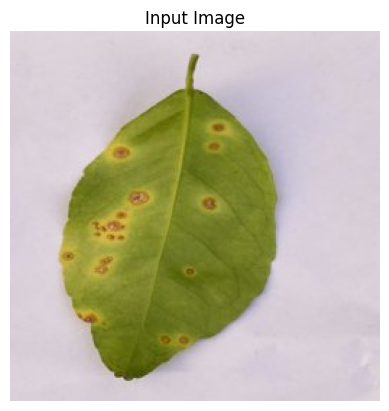

=== HASIL PREDIKSI ===

>>> CNN
Tanaman  : lettuce (100.00%)
Penyakit : Downy_mildew (99.82%)

>>> CNN + SVM
Tanaman  : lettuce (98.43%)
Penyakit : Downy_mildew (88.57%)

=== PERBANDINGAN ===
Tanaman sama? YA
Penyakit sama? YA


In [105]:
from google.colab import files
uploaded = files.upload()
IMG_SIZE = 128
RESNET_IMG_SIZE = 128
for filename in uploaded.keys():
    predict_compare(filename)